# 01 · Initial EDA: how “Bismillah c’est les ténèbres” spread

First look at the data collected by `uv run tenebres collect all`, then `process`, `fetch-articles` and `enrich`.
Every section skips itself if its source hasn't been collected yet, so you can re-run this notebook as data comes in.

**Questions in this pass**
1. *When and where did it start?* First appearances on each platform and in the news.
2. *How did it travel?* Volume over time on each platform, the order in which countries and language editions picked it up.
3. *Who covered it and how?* News by country and political leaning, how headlines frame it, sentiment.
4. *What do people say alongside it?* Engagement, influential accounts, cascades, links, first-pass topics.

Figures are saved to `reports/figures/`. The write-up is in `reports/initial_eda.md`.

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from tenebres.common import PROCESSED, strip_accents
from tenebres.viz import (setup, savefig, annotate_events, SERIES, SOURCE_COLORS,
                          LEANING_ORDER, LEANING_COLORS, INK_2, MUTED)

setup()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

def load(name):
    p = PROCESSED / f"{name}.parquet"
    return pd.read_parquet(p) if p.exists() else None

news = load("news_scored")
if news is None:
    news = load("news_articles")
if "on_topic" in news:  # drop off-topic Google News hits (see methodology)
    print(f"news: {news['on_topic'].sum()} on-topic of {len(news)} collected")
    news = news[news["on_topic"]].copy()
social = load("social_posts_scored")
if social is None:
    social = load("social_posts")
edges = load("bluesky_edges")
gdelt = load("gdelt_timelines")
wiki_pv = load("wiki_pageviews")
wiki_rev = load("wiki_revisions")

for df in (news, social):
    if df is not None:
        df["date"] = pd.to_datetime(df["date"])

# Key moments, from press coverage and Wikipedia (see docs/background.md)
EVENTS = {
    "2026-10-05": "screenshots circulate",
    "2026-10-09": "Brussels placards",
    "2026-10-13": "day of action + Greta",
    "2026-10-17": "riots",
    "2026-10-21": "intl explainers",
}
DATE_FMT = mdates.DateFormatter("%d %b")

summary = {
    "news articles (unique)": None if news is None else len(news),
    "social posts": None if social is None else len(social),
    "Bluesky repost/quote edges": None if edges is None else len(edges),
    "GDELT timeline points": None if gdelt is None else len(gdelt),
    "Wikipedia editions": None if wiki_pv is None else wiki_rev["lang"].nunique(),
}
pd.Series(summary, name="rows").to_frame()

news: 190 on-topic of 203 collected


,rows
news articles (unique),190.0
social posts,1268.0
Bluesky repost/quote edges,3699.0
GDELT timeline points,NaN
Wikipedia editions,5.0


## 1 · Where did it start? First appearances

Earliest items on each platform. The slogan comes from a screenshot of a Snapchat message, so the true “patient zero” is on Snapchat, TikTok or Instagram, which we can't search. These tables show **when it reached each platform we can observe**.

> 🔒 This cell's output shows usernames, so it is **cleared in the committed copy**. Run it locally to see it, and clear it again before committing (Edit → Clear Outputs of Selected Cells).

In [ ]:
if social is not None:
    for plat, g in social.groupby("platform"):
        print(f"\n=== {plat}: first 8 posts ===")
        display(g.nsmallest(8, "created_at")[["created_at", "author", "author_followers", "engagement", "text"]])

In [3]:
if news is not None:
    print("First 12 news articles")
    display(news.nsmallest(12, "published_at")[["published_at", "outlet", "country", "leaning", "title"]])

First 12 news articles


,published_at,outlet,country,leaning,title
2,2026-10-06 07:00:00+00:00,Nice-Matin,FR,center,"« Battle d’aura », « Bismillah c’est les ténèbres » : vous ne comprenez rien aux références des lycéens dans les blo..."
3,2026-10-07 07:00:00+00:00,NTD,US,right,School Blockades Continue Across France as Protesters Are Called to the Bastille
4,2026-10-09 07:00:00+00:00,Presse-citron,FR,center,Que signifie l’expression “Bismillah c’est les ténèbres” qu’on voit partout sur les réseaux sociaux ?
5,2026-10-10 07:00:00+00:00,La DH,BE,center,"D'où vient ""Bismillah c'est les ténèbres""? Une expression aperçue à de nombreuses reprises dans les manifestations"
6,2026-10-10 07:00:00+00:00,Anadolu Agency,TR,n/a,"France : « Bismillah c’est les ténèbres », des messages attribués à des policiers infiltrés deviennent un mème"
7,2026-10-10 07:00:00+00:00,HuffPost France,FR,center-left,"« Bismillah c’est les ténèbres », le mème né de l’infiltration raciste attribuée à des policiers sur Snapchat"
8,2026-10-10 07:00:00+00:00,La Libre Belgique,BE,center-right,"""Bismillah c'est les ténèbres"": que signifie cette expression brandie pendant les manifestations?"
9,2026-10-10 07:00:00+00:00,Yahoo Actualités,US,n/a,« Bismillah c'est les ténèbres » : l'infiltration raciste de policiers parmi les lycéens est devenue un mème
10,2026-10-12 07:00:00+00:00,NPA,FR,far-left,Autocollant : « Bismillah c'est les ténèbres »
11,2026-10-12 07:00:00+00:00,DNA,FR,center,"""Bismillah c'est les ténèbres"" : mais d'où vient ce nouveau slogan du mouvement lycéen ?"


## 2 · How did it travel? Attention over time

Each source is on its own scale, so this chart is **indexed to its peak day (= 100)**. That lets us compare *timing* without implying the volumes are comparable.

lemmy: 12 posts, left out of the indexed chart


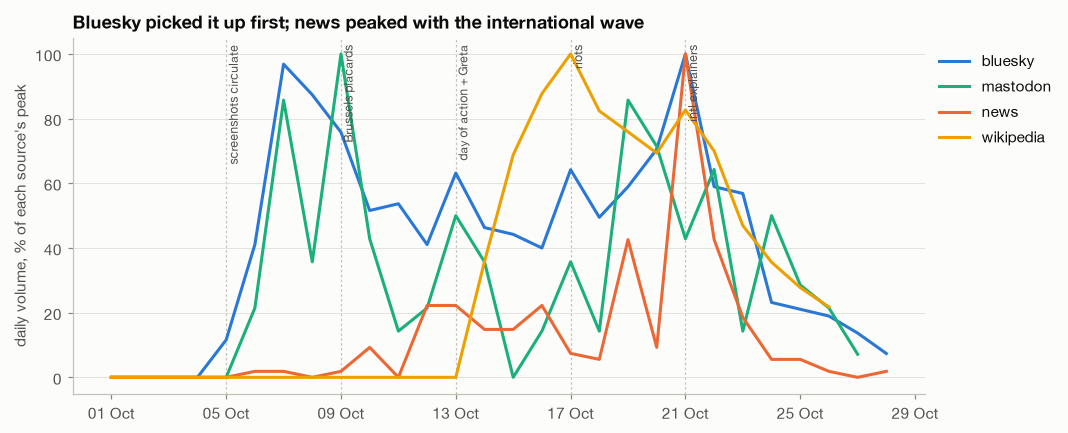

,2026-10-03,2026-10-04,2026-10-05,2026-10-06,2026-10-07,2026-10-08,2026-10-09,2026-10-10,2026-10-11,2026-10-12,...,2026-10-19,2026-10-20,2026-10-21,2026-10-22,2026-10-23,2026-10-24,2026-10-25,2026-10-26,2026-10-27,2026-10-28
bluesky,0,0,11,39,92,83,72,49,51,39,...,56,67,95,56,54,22,20,18,13,7
mastodon,0,0,0,3,12,5,14,6,2,3,...,12,10,6,9,2,7,4,3,1,0
news,0,0,0,1,1,0,1,5,0,12,...,23,5,54,23,10,3,3,1,0,1
wikipedia,0,0,0,0,0,0,0,0,0,0,...,25753,23522,28045,23738,15913,12080,9414,7382,4463,0


In [4]:
series = {}
if social is not None:
    for plat, g in social.groupby("platform"):
        if len(g) < 50:  # too few to index: one post a day would read as a "peak"
            print(f"{plat}: {len(g)} posts, left out of the indexed chart")
            continue
        series[plat] = g.groupby("date").size()
if news is not None:
    series["news"] = news.groupby("date").size()
if wiki_pv is not None:
    pv = wiki_pv.assign(date=pd.to_datetime(wiki_pv["date"])).groupby("date")["views"].sum()
    series["wikipedia"] = pv
if gdelt is not None:
    vol = gdelt[(gdelt["mode"] == "timelinevolraw") & (gdelt["series"] == "Article Count")]
    vol = vol.assign(date=pd.to_datetime(vol["date"].str[:8])).groupby("date")["value"].max()
    series["gdelt"] = vol

idx = pd.date_range("2026-10-01", max(s.index.max() for s in series.values()), freq="D")
fig, ax = plt.subplots(figsize=(10, 4.2))
for name, s in series.items():
    s = s[s.index < s.index.max()] if name == "wikipedia" else s  # last pageview day is partial
    s = s.reindex(idx).fillna(0).where(idx <= s.index.max())
    ax.plot(s.index, 100 * s / s.max(), label=name, color=SOURCE_COLORS.get(name), lw=2)
annotate_events(ax, EVENTS)
ax.set_ylabel("daily volume, % of each source's peak")
ax.xaxis.set_major_formatter(DATE_FMT)
ax.set_title("Bluesky picked it up first; news peaked with the international wave")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
savefig(fig, "01_attention_indexed")
plt.show()

pd.DataFrame({k: v.reindex(idx, fill_value=0) for k, v in series.items()}).loc["2026-10-03":].T

### Language mix on social media

Did the conversation stay francophone, or did other languages pick it up later?

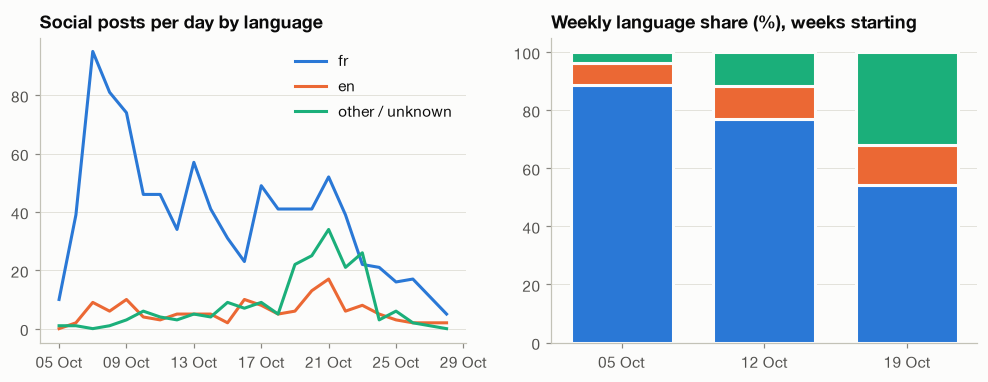

lang_group,fr,en,other / unknown,total
date,,,,
2026-10-05,391,34,16,441
2026-10-12,276,40,42,358
2026-10-19,232,58,137,427


In [5]:
if social is not None:
    lang = social["lang"].fillna("").str.split(";").str[0].replace("", "unknown")
    grp = lang.where(lang.isin(["fr", "en"]), "other / unknown")
    daily = social.assign(lang_group=grp).groupby(["date", "lang_group"]).size().unstack(fill_value=0)
    daily = daily.reindex(columns=["fr", "en", "other / unknown"], fill_value=0)
    share = daily.div(daily.sum(axis=1), axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for i, col in enumerate(daily.columns):
        axes[0].plot(daily.index, daily[col], label=col, color=SERIES[i])
    axes[0].set_title("Social posts per day by language")
    axes[0].legend()
    weekly = daily.resample("W-MON", label="left", closed="left").sum()
    weekly = weekly[weekly.sum(axis=1) >= 50]  # drop the partial current week
    wshare = weekly.div(weekly.sum(axis=1), axis=0) * 100
    bottom = np.zeros(len(wshare))
    for i, col in enumerate(wshare.columns):
        axes[1].bar(wshare.index, wshare[col], bottom=bottom, width=5, color=SERIES[i],
                    label=col, edgecolor="#fcfcfb", linewidth=2)
        bottom += wshare[col].values
    axes[1].set_title("Weekly language share (%), weeks starting")
    axes[1].set_xticks(wshare.index)
    for ax in axes:
        ax.xaxis.set_major_formatter(DATE_FMT)
    savefig(fig, "02_social_language")
    plt.show()
    display(weekly.assign(total=weekly.sum(axis=1)))

## 3 · News coverage: who, where, and how

### 3a · Countries: the order in which they picked it up

,first_article,articles,example_outlet
country,,,
FR,2026-10-06 07:00:00+00:00,59,Nice-Matin
US,2026-10-07 07:00:00+00:00,10,NTD
TR,2026-10-10 07:00:00+00:00,13,Anadolu Agency
BE,2026-10-10 07:00:00+00:00,9,La DH
CH,2026-10-12 07:00:00+00:00,7,Watson
CA,2026-10-13 12:06:40+00:00,5,Radio-Canada
IL,2026-10-14 07:00:00+00:00,1,i24NEWS
GR,2026-10-15 07:00:00+00:00,1,Newsfire
SA,2026-10-15 07:29:34+00:00,4,Arab News (FR)


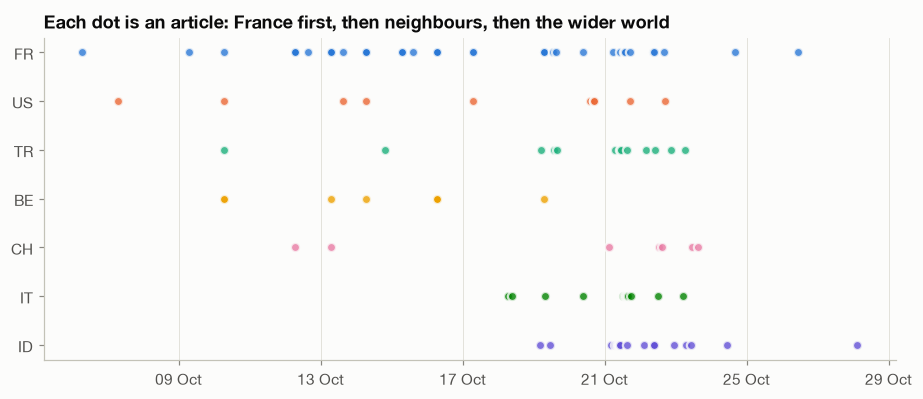

In [6]:
if news is not None:
    first = (news.groupby("country")
                 .agg(first_article=("published_at", "min"), articles=("title", "size"),
                      example_outlet=("outlet", "first"))
                 .sort_values("first_article"))
    display(first)

    top = news["country"].value_counts().index[:7]
    sub = news[news["country"].isin(top)]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    order = first.index[first.index.isin(top)]
    for i, c in enumerate(order):
        d = sub[sub["country"] == c]
        ax.scatter(d["published_at"], [i] * len(d), s=36, color=SERIES[i % 8], alpha=0.8,
                   edgecolor="#fcfcfb", linewidth=1.5)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(DATE_FMT)
    ax.set_title("Each dot is an article: France first, then neighbours, then the wider world")
    savefig(fig, "03_news_country_timeline")
    plt.show()

### 3b · Political leaning of outlets

Leaning comes from the **draft** outlet coding in `config/outlets.csv` (7-point scale; `n/a` = wires, state media, platforms; `uncoded` = not yet in the table). **The codes need team review before any inference.** See `docs/methodology.md`.

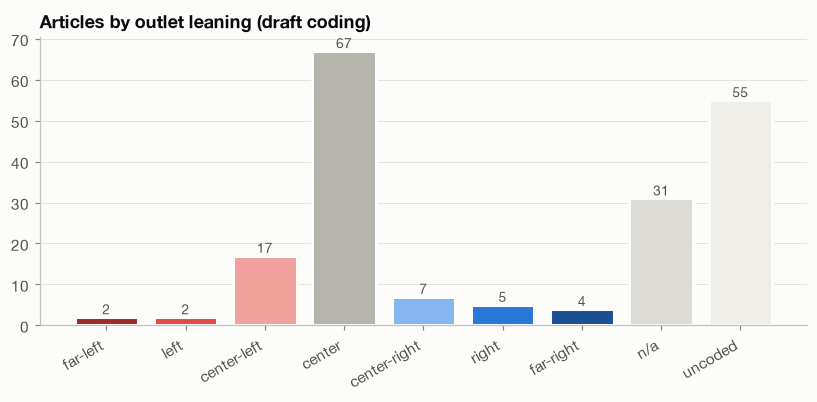

French outlets only:


,articles,outlets
leaning,,
far-left,2,"L'Anticapitaliste (NPA), NPA"
left,2,Libération
center-left,2,"HuffPost France, Le Monde"
center,39,"20 Minutes, Actu.fr, BFMTV, DNA, Euronews, France 24, Journal du Geek, L'Est républicain"
center-right,1,Le Point
right,3,Le Figaro
far-right,4,"Boulevard Voltaire, Le Journal du Dimanche, Reinformation.tv, Valeurs actuelles"
n/a,6,"AgoraVox, Closer, Le Gorafi, Monte Carlo Doualiya, The Local France"


In [7]:
if news is not None:
    cats = LEANING_ORDER + ["n/a", "uncoded"]
    counts = news["leaning"].value_counts().reindex(cats, fill_value=0)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.bar(counts.index, counts.values, color=[LEANING_COLORS[c] for c in counts.index],
           edgecolor="#fcfcfb", linewidth=2)
    for x, v in enumerate(counts.values):
        ax.text(x, v, str(v), ha="center", va="bottom", fontsize=9, color=INK_2)
    ax.set_title("Articles by outlet leaning (draft coding)")
    plt.xticks(rotation=30, ha="right")
    savefig(fig, "04_news_leaning")
    plt.show()

    fr = news[news["country"] == "FR"]
    print("French outlets only:")
    display(fr.groupby("leaning").agg(articles=("title", "size"),
                                      outlets=("outlet", lambda s: ", ".join(sorted(set(s))[:8])))
              .reindex([c for c in cats if c in set(fr["leaning"])]))

### 3c · Framing: what is the slogan written *about*?

A transparent first pass using **keyword dictionaries** on the headline plus the paragraph around the slogan (the `fetch-articles` context window). Each article can carry several frames. This is a starting point for proper qualitative coding, not a substitute for it.

% of articles mentioning each frame, by leaning bloc


bloc,centre,left bloc,n/a or uncoded,right bloc
n,67.0,21.0,86.0,16.0
explainer (what does it mean?),51.0,24.0,15.0,25.0
police infiltration,54.0,24.0,36.0,38.0
racism / stereotype,4.0,5.0,12.0,0.0
youth / school movement,69.0,52.0,29.0,56.0
violence / riots,0.0,10.0,3.0,12.0
Islam / religion,13.0,5.0,14.0,19.0
meme / humour,42.0,33.0,40.0,38.0
Greta Thunberg,16.0,0.0,5.0,0.0
spread abroad,12.0,24.0,17.0,0.0


% of articles mentioning each frame, French vs non-French outlets


scope,French outlets,non-French outlets
n,59.0,131.0
explainer (what does it mean?),46.0,22.0
police infiltration,49.0,37.0
racism / stereotype,7.0,8.0
youth / school movement,64.0,40.0
violence / riots,3.0,4.0
Islam / religion,14.0,13.0
meme / humour,34.0,42.0
Greta Thunberg,12.0,6.0
spread abroad,15.0,15.0


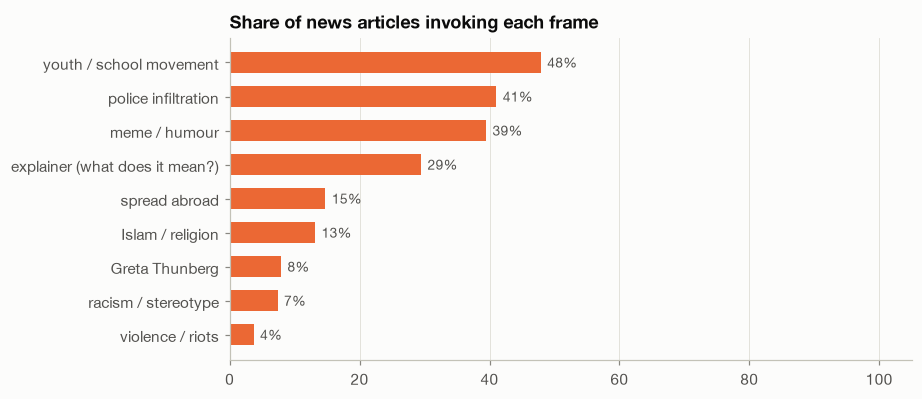

In [8]:
FRAMES = {
    "explainer (what does it mean?)": r"que signifie|que veut dire|d.ou vient|c.est quoi|what does|meaning|\bmean\b|explain|expliqu|decrypt|significa|vuol dire|bedeutet|origine|origin",
    "police infiltration": r"infiltr|polic|flic|undercover|snapchat|mamadou|agent",
    "racism / stereotype": r"racis|stereotyp|cliche|caricatur|discrimin|irkc",
    "youth / school movement": r"lycee|lyceen|student|etudiant|eleve|blocus|blocage|jeune|youth|studenti|schul|ogrenci",
    "violence / riots": r"emeute|violen|casse|pillag|riot|loot|degrad|scontri|krawall",
    "Islam / religion": r"islam|musulman|muslim|religi|allah|islamis",
    "meme / humour": r"\bmeme|viral|humour|humor|blague|moqu|mock|parod|tiktok|trend|ironi",
    "Greta Thunberg": r"greta|thunberg",
    "spread abroad": r"itali|belgi|bologn|milan|berlin|bruxelles|brussels|europe",
}

if news is not None:
    ctx = news["first_context"].fillna("") if "first_context" in news else ""
    text = (news["title"].fillna("") + " " + ctx).map(lambda t: strip_accents(t).lower())
    for f, pat in FRAMES.items():
        news[f] = text.str.contains(pat, regex=True)

    bloc = news["leaning"].map({
        "far-left": "left bloc", "left": "left bloc", "center-left": "left bloc",
        "center": "centre", "center-right": "right bloc", "right": "right bloc",
        "far-right": "right bloc"}).fillna("n/a or uncoded")
    news["bloc"] = bloc
    news["scope"] = np.where(news["country"] == "FR", "French outlets", "non-French outlets")

    frame_cols = list(FRAMES)
    by_bloc = news.groupby("bloc")[frame_cols].mean().mul(100).round(0)
    by_bloc.insert(0, "n", news.groupby("bloc").size())
    by_scope = news.groupby("scope")[frame_cols].mean().mul(100).round(0)
    by_scope.insert(0, "n", news.groupby("scope").size())
    print("% of articles mentioning each frame, by leaning bloc")
    display(by_bloc.T)
    print("% of articles mentioning each frame, French vs non-French outlets")
    display(by_scope.T)

    overall = news[frame_cols].mean().sort_values() * 100
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(overall.index, overall.values, color=SERIES[1], height=0.6)
    for y, v in enumerate(overall.values):
        ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color=INK_2)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title("Share of news articles invoking each frame")
    ax.set_xlim(0, 105)
    savefig(fig, "05_news_frames")
    plt.show()

### 3d · Sentiment of coverage

Sentiment comes from `cardiffnlp/twitter-xlm-roberta-base-sentiment` (multilingual) on the **headline** and on the **slogan's context paragraph**. Score = P(positive) − P(negative), in [-1, 1].

In [9]:
if news is not None and "title_sent_score" in news:
    cols = ["title_sent_score"] + (["ctx_sent_score"] if "ctx_sent_score" in news else [])
    display(news.groupby("bloc")[cols].agg(["mean", "count"]).round(2))
    display(news.groupby("scope")[cols].agg(["mean", "count"]).round(2))
    print("Most negative and most positive context windows:")
    if "ctx_sent_score" in news:
        show = ["outlet", "leaning", "ctx_sent_score", "first_context"]
        display(news.dropna(subset=["ctx_sent_score"]).nsmallest(5, "ctx_sent_score")[show])
        display(news.dropna(subset=["ctx_sent_score"]).nlargest(5, "ctx_sent_score")[show])
else:
    print("Run `uv run tenebres enrich` to add sentiment scores.")

title_sent_score       ctx_sent_score      
                           mean count           mean count
bloc                                                      
centre                    -0.33    67          -0.29    54
left bloc                 -0.32    21          -0.36    13
n/a or uncoded            -0.29    86          -0.35    75
right bloc                -0.51    16          -0.62    12

title_sent_score       ctx_sent_score      
                               mean count           mean count
scope                                                         
French outlets                -0.33    59          -0.36    48
non-French outlets            -0.32   131          -0.35   106

Most negative and most positive context windows:


,outlet,leaning,ctx_sent_score,first_context
145,la Repubblica,center-left,-0.920088,"Agli inizi di ottobre, in una chat Snapchat usata dagli studenti francesi per organizzare le manifestazioni, compare..."
146,The Business Standard,uncoded,-0.891350,"'Bismillah, c'est les ténèbres': What does the slogan mean, and why are French students using it? The phrase, mixing..."
191,NZZ,center-right,-0.886686,"«Bismillah, c’est les ténèbres» – wie ein sinnfreier Spruch zum Slogan des französischen Protests wurde Er ist übera..."
37,France 24,center,-0.881142,"""بسم الله، إنها الظلمات""… طلبة محتجون في فرنسا يتهمون الشرطة بمحاولة اختراقهم عبر حسابات وهمية أغرقت مواقع التواصل ا..."
7,HuffPost France,center-left,-0.869845,"« Bismillah c’est les ténèbres. » Depuis quelques jours, au milieu de la colère des lycéens, cette phrase est partou..."


,outlet,leaning,ctx_sent_score,first_context
171,20 minutes (CH),center,0.712667,"Manifestations en France«Bismillah, c'est les ténèbres»: un slogan qui intrigue Des centaines de milliers de personn..."
172,L'essentiel,center,0.712667,"Manifestations en France«Bismillah, c'est les ténèbres»: un slogan qui intrigue Des centaines de milliers de personn..."
20,Watson,center,0.545070,"«Bismillah c'est les ténèbres»: c'est quoi cette phrase déjà culte? Si vous avez internet, il y a de fortes chances ..."
161,Hasanah.id,uncoded,0.519741,"Arti Bismillah C’est Les Tenebres yang Viral saat Demo Prancis, Ternyata Berawal dari Meme - account_circle Talhah L..."
181,RRI,n/a,0.383938,"Fenomena Slogan ""Bismillah, C'est Les Ténèbres"" dalam Gelombang Aksi Protes di Prancis - 23 Okt 2026 05:54 WIB - Bin..."


## 4 · Social media: who amplified it and what came with it

### 4a · Engagement is extremely concentrated

Bluesky: 1136 posts, 19,539 total engagements (likes+reposts+replies+quotes)
Top 1% of posts hold 34% of engagement; top 10% hold 81%
Median post engagement: 2; 27% of posts got none


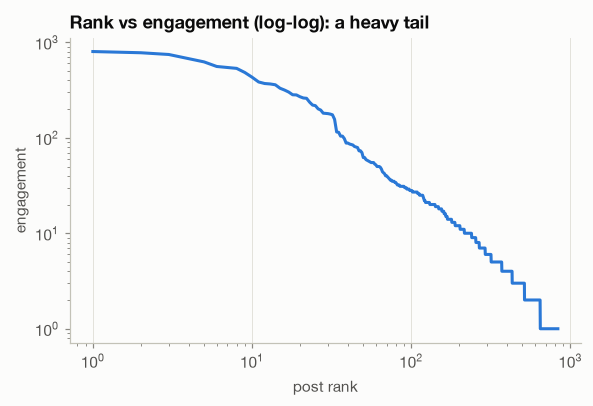

In [10]:
if social is not None:
    bs = social[social["platform"] == "bluesky"].copy()
    e = bs["engagement"].sort_values(ascending=False).values
    top1 = e[: max(1, len(e) // 100)].sum() / e.sum()
    top10 = e[: max(1, len(e) // 10)].sum() / e.sum()
    print(f"Bluesky: {len(bs)} posts, {e.sum():,} total engagements (likes+reposts+replies+quotes)")
    print(f"Top 1% of posts hold {top1:.0%} of engagement; top 10% hold {top10:.0%}")
    print(f"Median post engagement: {np.median(e):.0f}; {np.mean(e == 0):.0%} of posts got none")

    fig, ax = plt.subplots(figsize=(6, 3.6))
    x = np.sort(e[e > 0])[::-1]
    ax.loglog(np.arange(1, len(x) + 1), x, color=SOURCE_COLORS["bluesky"], lw=2)
    ax.set_xlabel("post rank"); ax.set_ylabel("engagement")
    ax.set_title("Rank vs engagement (log-log): a heavy tail")
    ax.grid(axis="both", which="major")
    savefig(fig, "06_engagement_tail")
    plt.show()

### 4b · Most influential accounts

> 🔒 This cell's output shows usernames, so it is **cleared in the committed copy**. Run it locally to see it, and clear it again before committing (Edit → Clear Outputs of Selected Cells).

In [ ]:
if social is not None:
    acct = (social.groupby(["platform", "author"])
                  .agg(posts=("post_id", "size"), engagement=("engagement", "sum"),
                       followers=("author_followers", "max"), first_post=("created_at", "min"))
                  .sort_values("engagement", ascending=False))
    display(acct.head(20))
    print("Share of engagement from the top 20 accounts:",
          f"{acct['engagement'].head(20).sum() / acct['engagement'].sum():.0%}")

### 4c · Cascades on Bluesky

For the 40 most-shared posts we pulled who reposted and who quoted them. Quote posts carry timestamps, so they show how long a post kept travelling.

In [12]:
if edges is not None and social is not None:
    reposts = edges[edges["type"] == "repost"]
    quotes = edges[edges["type"] == "quote"].copy()
    print(f"{reposts['source'].nunique():,} distinct accounts reposted at least one of the top-40 posts")
    multi = reposts.groupby("source").size()
    print(f"{(multi > 1).mean():.0%} of them reposted more than one top post (a core amplifier group)")
    print(f"{len(quotes)} quote posts")

    quotes["created_at"] = pd.to_datetime(quotes["created_at"], utc=True, format="ISO8601")
    parent_time = social.set_index("post_id")["created_at"]
    quotes["lag_hours"] = (quotes["created_at"] - quotes["target"].map(parent_time)).dt.total_seconds() / 3600
    if quotes["lag_hours"].notna().any():
        print("Hours from original post to quote: median "
              f"{quotes['lag_hours'].median():.1f}, 90th percentile {quotes['lag_hours'].quantile(.9):.1f}")

1,952 distinct accounts reposted at least one of the top-40 posts
33% of them reposted more than one top post (a core amplifier group)
219 quote posts
Hours from original post to quote: median 8.2, 90th percentile 42.1


### 4d · Which links travelled with the slogan?

Domains linked from social posts are the bridge between news and social media: which coverage got shared?

In [13]:
if social is not None:
    from tenebres.process import load_outlets, match_outlet
    outlets = load_outlets()
    links = social.dropna(subset=["link_domain"]).copy()
    links["leaning"] = [match_outlet(d, outlets).get("leaning", "uncoded") for d in links["link_domain"]]
    display(links.groupby(["link_domain", "leaning"]).size().sort_values(ascending=False).head(20).rename("posts"))

link_domain        leaning    
static.klipy.com   uncoded        25
heidi.news                        18
youtube.com        n/a            15
nytimes.com        center-left     9
youtu.be           n/a             7
briefly.co         uncoded         7
lightnews.app      uncoded         6
fr.wikipedia.org   uncoded         5
tinyurl.com        uncoded         4
france24.com       center          4
middleeasteye.net  center-left     4
euronews.com       center          4
piaille.fr         uncoded         4
franceinfo.fr      center          4
liberation.fr      left            4
huffingtonpost.fr  center-left     3
volkskrant.nl      uncoded         3
lemonde.fr         center-left     3
aljazeera.com      n/a             3
radiofrance.fr     center-left     3
Name: posts, dtype: int64

### 4e · Sentiment and toxicity of social posts

**Scores are computed with the slogan masked** (replaced by `«slogan»`), because the slogan alone moves both models: the bare slogan reads as 88% “positive” and 20% “toxic”. The probes below show the toxicity comes from “ténèbres” (darkness), not from “Bismillah”, so the feared identity-term bias isn't what drives it here. A hand-coded sample is still needed before reporting anything.

Sentiment of the text AROUND the slogan (slogan masked):


sent_label,negative,neutral,positive
platform,,,
bluesky,0.43,0.35,0.22
lemmy,0.58,0.33,0.08
mastodon,0.38,0.43,0.18


Mean score, raw text vs slogan masked (shows how much the slogan itself moves the model):


,sent_score_raw,sent_score
platform,,
bluesky,0.19,-0.17
lemmy,0.08,-0.29
mastodon,0.07,-0.13


Toxicity probability, distribution:


...

W1028 13:20:25.743000 74855 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 16921.04it/s]

Baseline probes (identity-term bias check):


,text,p_toxic
0,Bismillah c'est les ténèbres,0.203
1,C'est les ténèbres,0.218
2,Bismillah,0.084
3,Les lycéens manifestent contre la réforme,0.009


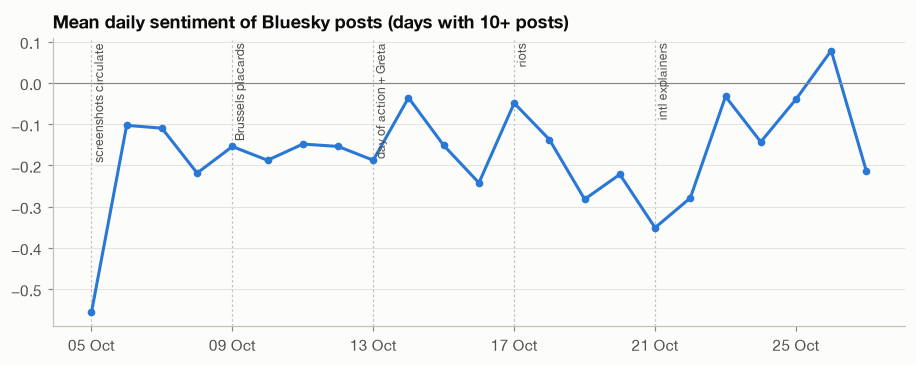

In [14]:
if social is not None and "sent_label" in social:
    print("Sentiment of the text AROUND the slogan (slogan masked):")
    display(pd.crosstab(social["platform"], social["sent_label"], normalize="index").round(2))
    print("Mean score, raw text vs slogan masked (shows how much the slogan itself moves the model):")
    display(social.groupby("platform")[["sent_score_raw", "sent_score"]].mean().round(2))
    tox_col = "tox_toxic" if "tox_toxic" in social else [c for c in social if c.startswith("tox_")][0]
    print("Toxicity probability, distribution:")
    display(social.groupby("platform")[tox_col].describe().round(3))

    from tenebres.enrich.nlp import _pipeline, TOXICITY_MODEL, SENTIMENT_MODEL
    tox = _pipeline("text-classification", TOXICITY_MODEL)
    probe = ["Bismillah c'est les ténèbres", "C'est les ténèbres", "Bismillah",
             "Les lycéens manifestent contre la réforme"]
    print("Baseline probes (identity-term bias check):")
    display(pd.DataFrame({"text": probe,
                          "p_toxic": [next(d["score"] for d in r if d["label"].lower() == "toxic")
                                      for r in tox(probe)]}).round(3))

    fig, ax = plt.subplots(figsize=(10, 3.4))
    daily = social[social["platform"] == "bluesky"].groupby("date")["sent_score"].agg(["mean", "size"])
    daily = daily[daily["size"] >= 10]
    ax.plot(daily.index, daily["mean"], color=SOURCE_COLORS["bluesky"], marker="o", ms=4)
    ax.axhline(0, color=MUTED, lw=0.8)
    annotate_events(ax, EVENTS)
    ax.xaxis.set_major_formatter(DATE_FMT)
    ax.set_title("Mean daily sentiment of Bluesky posts (days with 10+ posts)")
    savefig(fig, "07_social_sentiment")
    plt.show()
else:
    print("Run `uv run tenebres enrich` to add sentiment/toxicity.")

## 5 · First-pass topic model (BERTopic, social posts)

Multilingual sentence embeddings (`paraphrase-multilingual-MiniLM-L12-v2`) clustered with BERTopic. The slogan's own words are removed from the topic labels so they describe *what else* posts talk about. With ~1k short posts, treat topics as exploratory: re-run with different `min_topic_size` and read the example posts.

In [15]:
try:
    from bertopic import BERTopic
    from sklearn.feature_extraction.text import CountVectorizer
    HAVE_BERTOPIC = True
except ImportError:
    HAVE_BERTOPIC = False
    print("Install the NLP extra (uv sync --extra nlp) for topic modelling.")

if HAVE_BERTOPIC and social is not None:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    FR_STOP = ("au aux avec ce ces dans de des du elle en et eux il ils je la le les leur lui ma mais me même mes moi mon "
               "ne nos notre nous on ou par pas pour qu que qui sa se ses son sur ta te tes toi ton tu un une vos votre vous "
               "est sont été être ai as avons avez ont fait faire plus tout tous très bien comme si ça cette cet là y a c "
               "d l j n s t qu quand alors donc car aussi encore même rien sans sous chez elles ici non oui").split()
    SLOGAN = ["bismillah", "tenebres", "ténèbres", "cest", "c'est", "est", "les", "bismillahcestlestenebres", "darkness"]
    # Model what people say *besides* the slogan: mask it, strip links, drop
    # posts with fewer than 4 words left (bare repetitions of the slogan), and
    # drop exact duplicates (cross-posts, copy-pasted shares), which otherwise
    # form one dense cluster and collapse the rest into a single topic.
    from tenebres.common import load_config, mask_slogan
    cfg = load_config()
    body = (social["text"].map(lambda t: mask_slogan(t, cfg))
                          .str.replace("«slogan»", " ", regex=False)
                          .str.replace(r"https?://\S+|#", " ", regex=True))
    keep = (body.str.split().str.len() >= 4) & ~body.str.strip().duplicated()
    docs_df = social[keep].reset_index(drop=True)
    docs = body[keep].tolist()
    print(f"{len(docs)} of {len(social)} posts have 4+ words besides the slogan (exact duplicates dropped)")

    vectorizer = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS) + FR_STOP + SLOGAN,
                                 min_df=3, ngram_range=(1, 2), token_pattern=r"(?u)\b[^\W\d_]{3,}\b")
    from umap import UMAP
    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42)  # fixed seed = reproducible topics
    topic_model = BERTopic(embedding_model="paraphrase-multilingual-MiniLM-L12-v2", umap_model=umap_model,
                           vectorizer_model=vectorizer, min_topic_size=12)
    topics, _ = topic_model.fit_transform(docs)
    docs_df["topic"] = topics
    info = topic_model.get_topic_info()
    display(info[["Topic", "Count", "Name"]].head(20))

972 of 1268 posts have 4+ words besides the slogan (exact duplicates dropped)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2939.18it/s]

,Topic,Count,Name
0,-1,234,-1_meme_greta_com_trying
1,0,226,0_wesh_bon_maintenant_individus
2,1,148,1_france_french_slogan_student
3,2,88,2_vraiment_lumière_était_comprendre
4,3,62,3_flic_policier_écrit_succès
5,4,55,4_jeunes_lycéens_lycée_lycéen
6,5,45,5_policiers_snapchat_raciste_devenue
7,6,41,6_bsky social_youtube_bsky_youtube com
8,7,24,7_langage_lycéens_jeune_peu
9,8,24,8_droite_gauche_dire_essaye


In [16]:
if HAVE_BERTOPIC and social is not None:
    tops = info[info["Topic"] != -1].head(6)
    for t, name in zip(tops["Topic"], tops["Name"]):
        ex = docs_df[docs_df["topic"] == t].nlargest(3, "engagement")["text"].str.slice(0, 160).tolist()
        print(f"\n### Topic {t}: {name}")
        for x in ex:
            print("   •", x.replace("\n", " "))

    over = docs_df[docs_df["topic"].isin(tops["Topic"])]
    weekly = over.groupby([pd.Grouper(key="date", freq="W-MON", label="left", closed="left"), "topic"]).size().unstack(fill_value=0)
    weekly.columns = [info.set_index("Topic").loc[c, "Name"][:40] for c in weekly.columns]
    display(weekly)
    docs_df[["post_id", "platform", "date", "topic"]].merge(info[["Topic", "Name"]], left_on="topic", right_on="Topic") \
        .drop(columns="Topic").to_csv(PROCESSED / "social_topics.csv", index=False)


### Topic 0: 0_wesh_bon_maintenant_individus
   • « Bismillah c’est les ténèbres »  Résumé d'un coup (de la flicaille) raté :
   • Bismillah c’est les ténèbres dites voir mes braves brigands, qui parmi les fripouilles a prévu de mettre le binz ces jours ci ? Ajoutez moi au groupe de la chie
   • Moi je fête plus Bismillah c'est les ténèbres, c'est devenu une fête commerciale

### Topic 1: 1_france_french_slogan_student
   • "Bismillah c'est les ténèbres" scandé en français par des manifestants Italiens, c'était sur le bingo de qui ? ^^  Source : GTYannou sur Reddit /Aujourdhuijaiap
   • As hundreds of thousands of people took to the streets across France in support of student protesters, many displayed a rallying cry: “Bismillah, c’est les ténè
   • A Lyon, via @ Rebellyon # Bismillahcestlestenebres https:// rebellyon.info/Lyon-capitale-d u-zbeul-suivi-des-actions-41210?debut_maj=-1#pagination_maj&amp;gid=1

### Topic 2: 2_vraiment_lumière_était_comprendre
   • Bismillah c’est pas les

,0_wesh_bon_maintenant_individus,1_france_french_slogan_student,2_vraiment_lumière_était_comprendre,3_flic_policier_écrit_succès,4_jeunes_lycéens_lycée_lycéen,5_policiers_snapchat_raciste_devenue
date,,,,,,
2026-10-05,114,11,34,23,8,16
2026-10-12,64,33,25,18,25,19
2026-10-19,45,98,24,20,18,10
2026-10-26,3,6,5,1,4,0


## 6 · Wikipedia: which language communities documented it, and when

In [17]:
if wiki_rev is not None:
    created = (wiki_rev.assign(timestamp=pd.to_datetime(wiki_rev["timestamp"]))
                       .groupby("lang").agg(created=("timestamp", "min"), edits=("timestamp", "size"),
                                            editors=("user", "nunique")).sort_values("created"))
    display(created)
if wiki_pv is not None:
    pv = wiki_pv.assign(date=pd.to_datetime(wiki_pv["date"])).pivot_table(index="date", columns="lang", values="views", aggfunc="sum")
    display(pv.fillna(0).astype(int))

,created,edits,editors
lang,,,
en,2026-10-14 07:09:57+00:00,70,34
fr,2026-10-14 07:24:28+00:00,191,76
eu,2026-10-19 14:14:46+00:00,6,1
fa,2026-10-20 05:40:56+00:00,5,1
id,2026-10-21 02:28:17+00:00,1,1


lang,en,eu,fa,fr,id
date,,,,,
2026-10-14,0,0,0,12151,0
2026-10-15,0,0,0,23347,0
2026-10-16,8,0,0,29751,0
2026-10-17,1142,0,0,32782,0
2026-10-18,1774,0,0,26172,0
2026-10-19,3578,42,0,22133,0
2026-10-20,2750,60,41,20671,0
2026-10-21,2171,32,104,25669,69
2026-10-22,2606,16,120,20949,47


## 7 · GDELT (global news monitoring)

GDELT adds machine-translated coverage in 65 languages plus a tone score per article. Its API was rate-limiting us during the first collection; re-run `uv run tenebres collect gdelt` and this section fills in.

In [18]:
if gdelt is not None:
    for mode in ["timelinesourcecountry", "timelinelang"]:
        g = gdelt[gdelt["mode"] == mode]
        tot = g.groupby("series")["value"].sum().sort_values(ascending=False)
        print(mode); display(tot.head(15))
    tone = gdelt[gdelt["mode"] == "timelinetone"]
    display(tone.groupby(tone["date"].str[:8])["value"].mean().round(2).rename("avg tone").to_frame().T)
else:
    print("No GDELT data yet.")

No GDELT data yet.


## Next steps

See `reports/initial_eda.md` for findings and the open questions to take into the next round of analysis.